# UTS Machine Learning — Task 2: Fraud Classification

**Objective:** estimate transaction fraud probability and flag transactions for manual review under a review cost of Rp25,000 per flagged transaction.

**Data:** `klasifikasi_train.csv.gz`, `klasifikasi_test.csv.gz`, and `kamus_data.md` from the supplied dataset archive.

**Reproducibility:** run this notebook from top to bottom in Google Colab. The setup cells mount Google Drive and extract `data_uts_ml.zip` from `MyDrive/UTS_ML/`.

**Important evaluation note:** the chronological validation period shows material drift: August PR-AUC is 0.2962, versus 0.7223 in July. Test predictions are generated for September–October 2025, for which labels are not supplied in this project. Treat probabilities and review flags as model outputs, not verified test performance.


In [36]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
# 1. ENVIRONMENT AND REPRODUCIBILITY

import os
import zipfile
import random
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

warnings.filterwarnings("default")

# Plot settings
sns.set_theme(style="whitegrid")

print("Environment successfully initialized.")
print("Random seed:", SEED)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment successfully initialized.
Random seed: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:
# 2. DATASET EXTRACTION

ZIP_PATH = "/content/drive/MyDrive/UTS_ML/data_uts_ml.zip"
DATA_DIR = "/content/uts_ml_data"

assert os.path.exists(ZIP_PATH), "ZIP file not found!"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    zip_ref.extractall(DATA_DIR)

print("Extraction completed.")

print("\nFiles available:")

for filename in sorted(os.listdir(DATA_DIR)):
    filepath = os.path.join(DATA_DIR, filename)

    if os.path.isfile(filepath):
        print(
            filename,
            "|",
            round(os.path.getsize(filepath) / (1024**2), 2),
            "MB"
        )

Extraction completed.

Files available:
clustering.csv.gz | 14.96 MB
kamus_data.md | 0.0 MB
klasifikasi_test.csv.gz | 17.39 MB
klasifikasi_train.csv.gz | 65.42 MB
regresi_test.csv.gz | 8.3 MB
regresi_train.csv.gz | 35.35 MB


In [39]:

# ==========================================
# TASK 2: FRAUD CLASSIFICATION
# STEP 1A: ENVIRONMENT INITIALIZATION
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

DATA_DIR = "/content/uts_ml_data"

TRAIN_PATH = os.path.join(
    DATA_DIR, "klasifikasi_train.csv.gz"
)

TEST_PATH = os.path.join(
    DATA_DIR, "klasifikasi_test.csv.gz"
)

assert os.path.exists(TRAIN_PATH), "Training file not found"
assert os.path.exists(TEST_PATH), "Testing file not found"

print("TASK 2 ENVIRONMENT INITIALIZED")
print("--------------------------------")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random seed:", RANDOM_STATE)
print("Data directory:", DATA_DIR)


TASK 2 ENVIRONMENT INITIALIZED
--------------------------------
Pandas: 2.2.3
NumPy: 2.4.6
Random seed: 42
Data directory: /content/uts_ml_data


In [40]:

# ==========================================
# STEP 1B: LOAD DATASETS
# ==========================================

cls_train = pd.read_csv(TRAIN_PATH)
cls_test = pd.read_csv(TEST_PATH)

print("DATASETS LOADED SUCCESSFULLY")
print("--------------------------------")

print("Training shape:", cls_train.shape)
print("Testing shape:", cls_test.shape)

print("\nTraining columns:", len(cls_train.columns))
print("Testing columns:", len(cls_test.columns))

display(cls_train.head())


DATASETS LOADED SUCCESSFULLY
--------------------------------
Training shape: (403077, 85)
Testing shape: (106674, 84)

Training columns: 85
Testing columns: 84


,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,umur_akun_hari,level_kyc,umur_pengguna_tahun,email_domain,umur_perangkat_hari,perangkat_baru,jumlah_akun_per_perangkat,ganti_password_7h,gagal_login_24j,jarak_lokasi_km,negara_ip_beda,kartu_tidak_hadir,menit_sejak_trx_terakhir,trx_1j,trx_24j,trx_7h,nominal_24j,rasio_nominal_rata2,saldo_sebelum,persen_saldo,umur_merchant_hari,refund_merchant_30h,volume_merchant_30h,flag_review_manual,v01,v02,v03,v04,v05,v06,v07,v08,v09,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,v38,v39,v40,v41,v42,v43,v44,v45,v46,v47,v48,v49,v50,is_fraud
0,T464739637,2025-07-19 19:30:41,U103280,M04468,kecantikan,qris,android,26600.0,19,0,28,1,38,gmail,0.0,0,1,0,0,9.2,0,0,12864.9,0,0,0,0.0,0.289,48000.0,0.554,2147,1.65,301,0,1.552,-0.492,-0.031,1.5,0.560,0.190,-0.156,0.533,1.5,-0.541,-0.929,0.710,-2.061,1.5,1.275,-1.540,-0.496,-0.452,1.535,0.599,1.651,-0.045,-0.003,-0.5,0.011,-1.388,-0.351,0.857,-0.821,0.782,-1.418,-0.607,3.396,-0.5,-0.258,-1.317,1.036,0.856,-0.5,-0.958,-0.213,0.350,0.814,-0.5,-1.018,1.378,0.232,0.142,-0.5,0.291,0
1,T555813708,2025-08-18 20:49:21,U127558,M02239,toko_online,aplikasi,android,179300.0,20,0,645,1,38,gmail,569.1,0,1,0,0,4.9,0,0,49041.1,0,0,0,0.0,0.350,1026000.0,0.175,989,0.77,2082,0,-0.241,-0.227,0.093,-0.5,-1.165,-0.849,1.782,1.257,-0.5,0.052,0.376,-0.654,2.195,-0.5,4.404,-0.939,-0.976,2.099,-1.857,0.010,-0.758,-0.175,-1.229,-0.5,0.583,0.450,-0.237,-0.146,0.325,0.779,-1.602,-0.051,0.492,-0.5,-0.360,0.250,-0.116,1.822,1.5,-0.345,-0.983,0.284,-0.464,1.5,-1.889,-1.051,0.434,-0.280,-0.5,-0.621,0
2,T998564616,2025-02-25 03:29:04,U100074,M01144,makanan_minuman,qris,android,58800.0,3,0,216,1,23,lainnya,0.0,0,1,0,0,2.3,0,0,NaN,0,0,0,0.0,NaN,222000.0,0.265,1980,1.86,1057,0,-1.566,-0.378,0.263,-0.5,-0.972,-1.618,-0.004,1.245,1.5,0.601,-1.311,0.282,-0.337,-0.5,2.276,-0.253,-0.302,1.157,-0.020,0.005,1.315,-0.313,1.207,-0.5,0.236,1.144,-0.202,-1.426,-0.324,-1.329,0.501,-0.007,2.066,-0.5,0.553,-0.491,0.061,2.402,-0.5,-0.906,-0.448,0.359,-0.172,1.5,0.252,-0.363,-1.452,0.260,1.5,-1.211,0
3,T221231710,2025-07-04 10:09:24,U108689,M01424,kesehatan,va,android,147400.0,10,0,930,1,35,gmail,849.2,0,1,0,0,19.3,0,0,221284.1,0,0,0,0.0,1.085,116000.0,1.271,248,0.97,2522,0,1.010,-0.649,2.741,-0.5,0.508,1.036,-0.643,0.005,-0.5,-0.816,0.305,1.983,-0.825,-0.5,1.663,-1.606,-0.356,-3.291,2.155,-0.629,1.094,-0.659,0.884,-0.5,1.025,-0.353,0.259,-0.914,-1.169,-0.224,-1.461,1.467,1.962,1.5,-1.370,0.916,0.065,1.425,1.5,0.868,0.869,0.876,-0.447,1.5,0.346,1.291,0.999,0.376,1.5,-2.059,0
4,T253111101,2025-08-28 23:09:19,U021647,M00684,elektronik,va,android,305400.0,23,0,567,1,17,gmail,542.6,0,1,0,0,9.9,0,0,12269.5,0,0,0,0.0,7.260,166000.0,1.840,331,1.75,274,0,1.691,-0.397,-0.383,1.5,0.650,-0.159,0.921,1.312,-0.5,-0.696,0.958,-0.510,-5.943,-0.5,0.713,-0.973,-0.041,-0.855,0.495,-1.348,-0.508,-0.055,0.773,-0.5,1.917,4.573,0.394,0.298,-1.001,-0.058,-1.184,-0.427,0.392,-0.5,-0.402,0.328,-0.369,1.146,-0.5,-0.708,-1.568,0.030,1.016,1.5,-0.368,-0.268,-0.430,0.581,-0.5,-0.799,0


In [41]:

# ==========================================
# STEP 1C: INITIAL DATA AUDIT
# ==========================================

print("INITIAL DATA AUDIT")
print("==================")

# Target and ID availability
print("\nTARGET AVAILABILITY")
print("Training:", "is_fraud" in cls_train.columns)
print("Testing:", "is_fraud" in cls_test.columns)

print("\nID UNIQUENESS")
print(
    "Training IDs unique:",
    cls_train["id_transaksi"].is_unique
)
print(
    "Testing IDs unique:",
    cls_test["id_transaksi"].is_unique
)

print(
    "Train-test ID overlap:",
    cls_train["id_transaksi"].isin(
        cls_test["id_transaksi"]
    ).sum()
)

# Duplicate records
print("\nDUPLICATE AUDIT")
print("Training duplicates:", cls_train.duplicated().sum())
print("Testing duplicates:", cls_test.duplicated().sum())

# Feature consistency
train_features = set(cls_train.columns) - {"is_fraud"}
test_features = set(cls_test.columns)

print("\nFEATURE CONSISTENCY")
print("Same feature sets:", train_features == test_features)
print("Missing from test:", train_features - test_features)
print("Unexpected in test:", test_features - train_features)

# Target validity
print("\nTARGET DISTRIBUTION")
display(
    cls_train["is_fraud"].value_counts(dropna=False)
    .to_frame("Count")
)

print("\nTARGET PROPORTIONS")
display(
    cls_train["is_fraud"]
    .value_counts(normalize=True, dropna=False)
    .to_frame("Proportion")
)

# Time coverage
cls_train["waktu"] = pd.to_datetime(
    cls_train["waktu"],
    errors="coerce"
)

cls_test["waktu"] = pd.to_datetime(
    cls_test["waktu"],
    errors="coerce"
)

print("\nDATE COVERAGE")
print("Training start:", cls_train["waktu"].min())
print("Training end:", cls_train["waktu"].max())
print("Testing start:", cls_test["waktu"].min())
print("Testing end:", cls_test["waktu"].max())

print("\nMONTHLY TRAINING RECORDS")
display(
    cls_train["waktu"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .to_frame("Transactions")
)


INITIAL DATA AUDIT

TARGET AVAILABILITY
Training: True
Testing: False

ID UNIQUENESS
Training IDs unique: True
Testing IDs unique: True
Train-test ID overlap: 0

DUPLICATE AUDIT
Training duplicates: 0
Testing duplicates: 0

FEATURE CONSISTENCY
Same feature sets: True
Missing from test: set()
Unexpected in test: set()

TARGET DISTRIBUTION


,Count
is_fraud,
0,400455
1,2622



TARGET PROPORTIONS


,Proportion
is_fraud,
0,0.993495
1,0.006505



DATE COVERAGE
Training start: 2025-01-01 00:02:53
Training end: 2025-08-31 23:58:04
Testing start: 2025-09-01 00:01:51
Testing end: 2025-10-31 23:57:22

MONTHLY TRAINING RECORDS


,Transactions
waktu,
2025-01,50432
2025-02,46240
2025-03,51048
2025-04,47413
2025-05,52331
2025-06,50375
2025-07,52334
2025-08,52904


In [42]:

# ==========================================
# TASK 2A: DETAILED FEATURE AUDIT
# ==========================================

# 1. Missing value analysis
missing_audit = pd.DataFrame({
    "missing_count": cls_train.isna().sum(),
    "missing_percentage": cls_train.isna().mean() * 100
})

missing_audit = missing_audit[
    missing_audit["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=False
)

print("MISSING VALUE AUDIT")
print("===================")
display(missing_audit)

# 2. Feature type and cardinality
feature_audit = pd.DataFrame({
    "dtype": cls_train.dtypes.astype(str),
    "unique_values": cls_train.nunique(),
    "missing_percentage": cls_train.isna().mean() * 100
})

feature_audit = feature_audit.sort_values(
    "unique_values",
    ascending=False
)

print("\nFEATURE TYPE AND CARDINALITY")
display(feature_audit)

# 3. Potentially sensitive or suspicious features
print("\nFEATURES REQUIRING TEMPORAL INVESTIGATION")

suspicious_features = [
    col for col in cls_train.columns
    if any(term in col.lower() for term in [
        "review", "refund", "fraud", "status",
        "label", "chargeback", "investigasi"
    ])
]

print(suspicious_features)

# 4. Target validity
print("\nTARGET VALIDITY")
print("Missing labels:", cls_train["is_fraud"].isna().sum())
print("Target values:", sorted(cls_train["is_fraud"].dropna().unique()))


MISSING VALUE AUDIT


,missing_count,missing_percentage
menit_sejak_trx_terakhir,102621,25.459404
rasio_nominal_rata2,102621,25.459404



FEATURE TYPE AND CARDINALITY


,dtype,unique_values,missing_percentage
id_transaksi,object,403077,0.000000
waktu,datetime64[ns],398219,0.000000
menit_sejak_trx_terakhir,float64,245886,25.459404
id_pengguna,object,102621,0.000000
nominal,float64,23829,0.000000
umur_perangkat_hari,float64,19810,0.000000
rasio_nominal_rata2,float64,15492,25.459404
persen_saldo,float64,13218,0.000000
v33,float64,10769,0.000000
v03,float64,10761,0.000000



FEATURES REQUIRING TEMPORAL INVESTIGATION
['refund_merchant_30h', 'flag_review_manual', 'is_fraud']

TARGET VALIDITY
Missing labels: 0
Target values: [np.int64(0), np.int64(1)]


MONTHLY FRAUD DISTRIBUTION


,total_transactions,fraud_transactions,fraud_percentage
waktu,,,
2025-01,50432,327,0.648398
2025-02,46240,301,0.650952
2025-03,51048,387,0.758110
2025-04,47413,355,0.748740
2025-05,52331,367,0.701305
2025-06,50375,299,0.593548
2025-07,52334,341,0.651584
2025-08,52904,245,0.463103


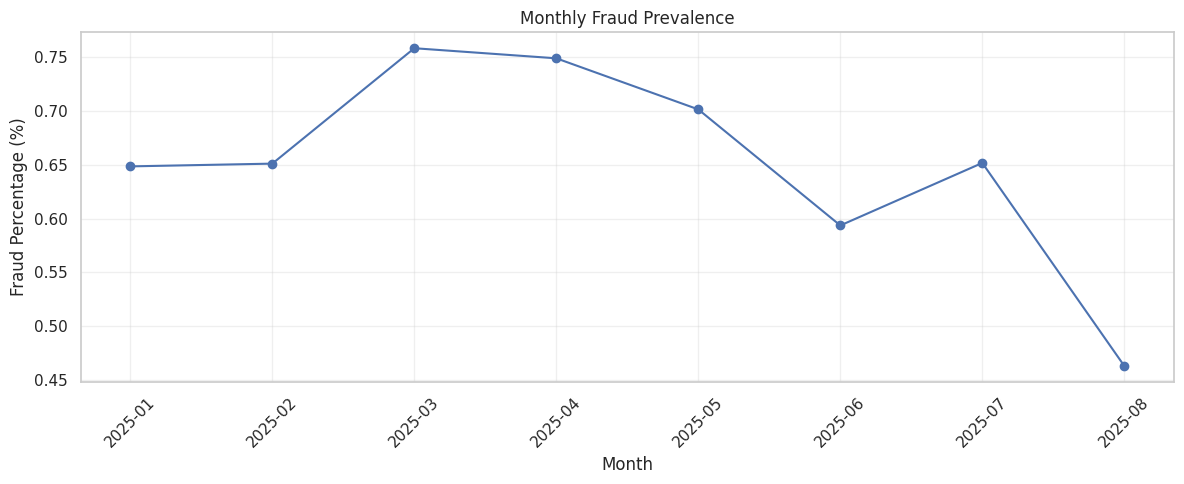

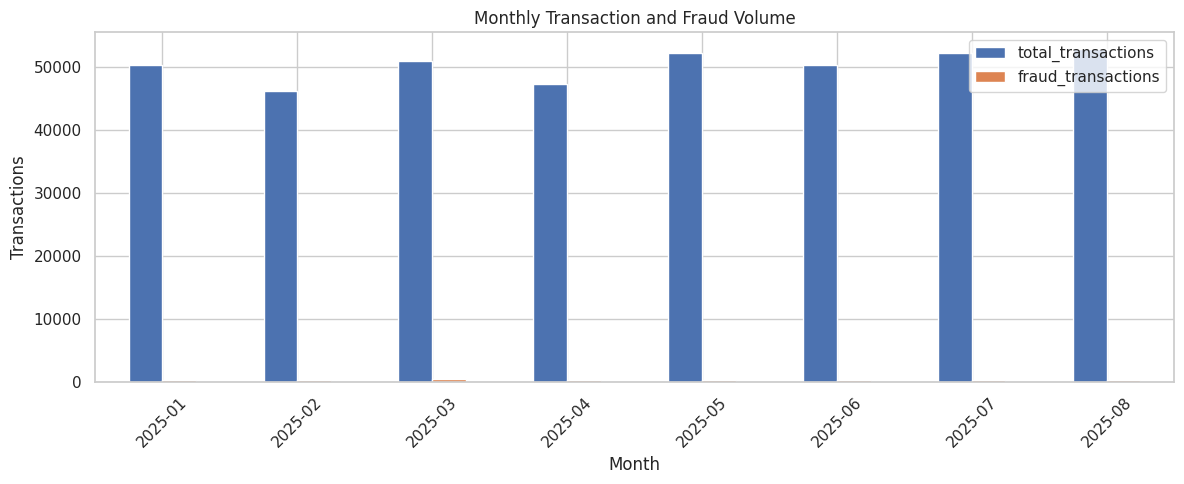

In [43]:

# ==========================================
# TASK 2A: FRAUD DISTRIBUTION OVER TIME
# ==========================================

monthly_fraud = (
    cls_train.groupby(
        cls_train["waktu"].dt.to_period("M")
    )
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum")
    )
)

monthly_fraud["fraud_percentage"] = (
    monthly_fraud["fraud_transactions"] /
    monthly_fraud["total_transactions"] * 100
)

print("MONTHLY FRAUD DISTRIBUTION")
display(monthly_fraud)

# Visualize fraud prevalence
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_fraud.index.astype(str),
    monthly_fraud["fraud_percentage"],
    marker="o"
)

plt.title("Monthly Fraud Prevalence")
plt.xlabel("Month")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Monthly fraud volume
monthly_fraud[
    ["total_transactions", "fraud_transactions"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Monthly Transaction and Fraud Volume")
plt.xlabel("Month")
plt.ylabel("Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [44]:

# ==========================================
# TASK 2A: FRAUD BY CATEGORY AND CHANNEL
# ==========================================

def fraud_rate_analysis(df, column):

    result = (
        df.groupby(column, dropna=False)
        .agg(
            transactions=("is_fraud", "size"),
            fraud_count=("is_fraud", "sum")
        )
    )

    result["fraud_rate"] = (
        result["fraud_count"] /
        result["transactions"] * 100
    )

    return result.sort_values(
        "fraud_rate",
        ascending=False
    )

print("FRAUD BY PAYMENT CHANNEL")
display(fraud_rate_analysis(cls_train, "kanal"))

print("\nFRAUD BY MERCHANT CATEGORY")
display(fraud_rate_analysis(cls_train, "kategori_merchant"))

print("\nFRAUD BY DEVICE TYPE")
display(fraud_rate_analysis(cls_train, "tipe_perangkat"))


FRAUD BY PAYMENT CHANNEL


,transactions,fraud_count,fraud_rate
kanal,,,
kartu,49517,840,1.696387
web,24842,419,1.686660
va,59921,537,0.896180
aplikasi,179979,642,0.356708
qris,88818,184,0.207165



FRAUD BY MERCHANT CATEGORY


,transactions,fraud_count,fraud_rate
kategori_merchant,,,
voucher_game,18016,427,2.370115
emas,6404,150,2.342286
gadget,17033,281,1.649739
top_up_ewallet,20815,232,1.114581
toko_online,32649,315,0.964807
pulsa_data,38660,308,0.796689
kecantikan,16917,123,0.727079
fashion,27573,196,0.710840
elektronik,44032,299,0.679052



FRAUD BY DEVICE TYPE


,transactions,fraud_count,fraud_rate
tipe_perangkat,,,
ios,80421,561,0.697579
web,32112,223,0.694444
android,290544,1838,0.632606


In [45]:

# ==========================================
# TASK 2A: MANUAL REVIEW FLAG AUDIT
# ==========================================

print("MANUAL REVIEW FLAG DISTRIBUTION")

display(
    pd.crosstab(
        cls_train["flag_review_manual"],
        cls_train["is_fraud"],
        margins=True
    )
)

print("\nFRAUD RATE BY MANUAL REVIEW FLAG")

display(
    fraud_rate_analysis(
        cls_train,
        "flag_review_manual"
    )
)

print("\nMANUAL REVIEW FLAG CORRELATION")

print(
    cls_train[
        ["flag_review_manual", "is_fraud"]
    ].corr()
)


MANUAL REVIEW FLAG DISTRIBUTION


is_fraud,0,1,All
flag_review_manual,,,
0,395652,527,396179
1,4803,2095,6898
All,400455,2622,403077



FRAUD RATE BY MANUAL REVIEW FLAG


,transactions,fraud_count,fraud_rate
flag_review_manual,,,
1,6898,2095,30.371122
0,396179,527,0.133021



MANUAL REVIEW FLAG CORRELATION
                    flag_review_manual  is_fraud
flag_review_manual             1.00000   0.48783
is_fraud                       0.48783   1.00000


In [46]:

# ==========================================
# TASK 2B: MISSINGNESS AND HISTORY AUDIT
# ==========================================

audit_df = cls_train.sort_values(
    ["id_pengguna", "waktu"]
).copy()

# Identify first observed transaction per user
audit_df["first_observed_transaction"] = (
    ~audit_df.duplicated(
        subset="id_pengguna",
        keep="first"
    )
)

# Identify missing historical features
audit_df["missing_history"] = (
    audit_df["menit_sejak_trx_terakhir"].isna()
)

audit_df["missing_ratio"] = (
    audit_df["rasio_nominal_rata2"].isna()
)

print("MISSINGNESS RELATIONSHIP")
print("========================")

print(
    "First observed transactions:",
    audit_df["first_observed_transaction"].sum()
)

print(
    "Missing previous transaction time:",
    audit_df["missing_history"].sum()
)

print(
    "Missing previous transaction ratio:",
    audit_df["missing_ratio"].sum()
)

print(
    "Missingness patterns identical:",
    audit_df["missing_history"].equals(
        audit_df["missing_ratio"]
    )
)

print("\nFIRST TRANSACTION VS MISSING HISTORY")

display(
    pd.crosstab(
        audit_df["first_observed_transaction"],
        audit_df["missing_history"],
        margins=True
    )
)

print("\nFRAUD RATE BY MISSING HISTORY")

display(
    audit_df.groupby("missing_history")["is_fraud"]
    .agg(["count", "sum", "mean"])
)

# Check whether historical features have impossible values
print("\nHISTORICAL FEATURE SUMMARY")

display(
    audit_df[
        [
            "menit_sejak_trx_terakhir",
            "trx_1j",
            "trx_24j",
            "trx_7h",
            "nominal_24j",
            "rasio_nominal_rata2"
        ]
    ].describe().T
)


MISSINGNESS RELATIONSHIP
First observed transactions: 102621
Missing previous transaction time: 102621
Missing previous transaction ratio: 102621
Missingness patterns identical: True

FIRST TRANSACTION VS MISSING HISTORY


missing_history,False,True,All
first_observed_transaction,,,
False,300455,1,300456
True,1,102620,102621
All,300456,102621,403077



FRAUD RATE BY MISSING HISTORY


,count,sum,mean
missing_history,,,
False,300456,1662,0.005532
True,102621,960,0.009355



HISTORICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
menit_sejak_trx_terakhir,300456.0,44446.573250,51448.683217,0.000,8831.350,25757.400,60607.275,3.472521e+05
trx_1j,403077.0,0.037415,0.307885,0.000,0.000,0.000,0.000,1.000000e+01
trx_24j,403077.0,0.071252,0.363576,0.000,0.000,0.000,0.000,1.000000e+01
trx_7h,403077.0,0.285464,0.682976,0.000,0.000,0.000,0.000,1.300000e+01
nominal_24j,403077.0,12794.317463,122179.987037,0.000,0.000,0.000,0.000,1.009620e+07
rasio_nominal_rata2,300456.0,1.774801,3.975896,0.001,0.298,0.704,1.770,5.177640e+02


In [47]:

# ==========================================
# TASK 2C: FEATURE TIMING INVESTIGATION
# ==========================================

# Compare selected features against the target
timing_candidates = [
    "flag_review_manual",
    "refund_merchant_30h",
    "volume_merchant_30h",
    "umur_merchant_hari",
    "trx_1j",
    "trx_24j",
    "trx_7h",
    "nominal_24j",
    "menit_sejak_trx_terakhir",
    "rasio_nominal_rata2"
]

timing_results = []

for col in timing_candidates:

    temp = cls_train.groupby("is_fraud")[col].agg(
        ["count", "mean", "median"]
    )

    timing_results.append({
        "feature": col,
        "legitimate_mean": temp.loc[0, "mean"],
        "fraud_mean": temp.loc[1, "mean"],
        "legitimate_median": temp.loc[0, "median"],
        "fraud_median": temp.loc[1, "median"]
    })

timing_audit = pd.DataFrame(timing_results)

display(timing_audit)


,feature,legitimate_mean,fraud_mean,legitimate_median,fraud_median
0,flag_review_manual,0.011994,0.799008,0.000,1.0000
1,refund_merchant_30h,1.352065,2.214546,1.170,1.4100
2,volume_merchant_30h,968.640771,919.545767,383.000,385.5000
3,umur_merchant_hari,1021.303717,804.654844,954.000,692.0000
4,trx_1j,0.031916,0.877193,0.000,0.0000
5,trx_24j,0.065933,0.883677,0.000,0.0000
6,trx_7h,0.281160,0.942792,0.000,0.0000
7,nominal_24j,11776.252762,168282.151030,0.000,0.0000
8,menit_sejak_trx_terakhir,44542.853841,27137.269374,25866.300,17.9500
9,rasio_nominal_rata2,1.769604,2.709049,0.701,1.2965


In [48]:

# ==========================================
# INVESTIGATE MISSINGNESS EXCEPTIONS
# ==========================================

exceptions = audit_df[
    audit_df["first_observed_transaction"]
    != audit_df["missing_history"]
]

display(
    exceptions[
        [
            "id_transaksi",
            "id_pengguna",
            "waktu",
            "first_observed_transaction",
            "missing_history",
            "menit_sejak_trx_terakhir",
            "rasio_nominal_rata2",
            "is_fraud"
        ]
    ]
)

# Fraud rate by historical status and month
audit_df["month"] = (
    pd.to_datetime(audit_df["waktu"]).dt.to_period("M")
)

monthly_history = (
    audit_df.groupby(["month", "missing_history"])
    ["is_fraud"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

monthly_history["fraud_rate_pct"] = (
    monthly_history["mean"] * 100
)

display(monthly_history)


,id_transaksi,id_pengguna,waktu,first_observed_transaction,missing_history,menit_sejak_trx_terakhir,rasio_nominal_rata2,is_fraud
50038,T995887798,U076273,2025-08-02 12:26:06,True,False,0.0,0.87,1
381028,T649205858,U076273,2025-08-02 12:26:06,False,True,NaN,NaN,1


,month,missing_history,count,sum,mean,fraud_rate_pct
0,2025-01,False,17702,154,0.008700,0.869958
1,2025-01,True,32730,173,0.005286,0.528567
2,2025-02,False,29035,154,0.005304,0.530394
3,2025-02,True,17205,147,0.008544,0.854403
4,2025-03,False,37579,243,0.006466,0.646638
5,2025-03,True,13469,144,0.010691,1.069122
6,2025-04,False,37679,231,0.006131,0.613074
7,2025-04,True,9734,124,0.012739,1.273885
8,2025-05,False,43420,244,0.005620,0.561953
9,2025-05,True,8911,123,0.013803,1.380316


In [49]:

# ==========================================
# BEHAVIORAL FEATURE ENGINEERING
# ==========================================

for df in [cls_train, cls_test]:

    df["missing_history"] = (
        df["menit_sejak_trx_terakhir"].isna()
    ).astype("int8")

    # Do not use flag_review_manual as a predictor
    # Retain the original columns for audit purposes.

print("Behavioral feature created.")

print(
    "Training missing-history rate:",
    round(cls_train["missing_history"].mean() * 100, 2),
    "%"
)

print(
    "Testing missing-history rate:",
    round(cls_test["missing_history"].mean() * 100, 2),
    "%"
)


Behavioral feature created.
Training missing-history rate: 25.46 %
Testing missing-history rate: 10.74 %


In [50]:

# ==========================================
# INVESTIGATE SAME-USER SAME-TIME RECORDS
# ==========================================

duplicate_time = cls_train[
    (cls_train["id_pengguna"] == "U076273") &
    (cls_train["waktu"] == "2025-08-02 12:26:06")
]

display(
    duplicate_time.sort_values("id_transaksi").T
)

# Check duplicate user-timestamp combinations
duplicate_user_times = (
    cls_train.groupby(
        ["id_pengguna", "waktu"]
    ).size()
)

print(
    "Repeated user-timestamp groups:",
    (duplicate_user_times > 1).sum()
)

print(
    "Records in repeated groups:",
    duplicate_user_times[duplicate_user_times > 1].sum()
)


,381028,50038
id_transaksi,T649205858,T995887798
waktu,2025-08-02 12:26:06,2025-08-02 12:26:06
id_pengguna,U076273,U076273
id_merchant,M06900,M07836
kategori_merchant,fashion,makanan_minuman
kanal,qris,qris
tipe_perangkat,android,android
nominal,2300000.0,2000000.0
jam,12,12
hari_libur,0,0


Repeated user-timestamp groups: 10
Records in repeated groups: 20


In [51]:

# ==========================================
# MISSING HISTORY DISTRIBUTION SHIFT
# ==========================================

train_history = cls_train.copy()
test_history = cls_test.copy()

train_history["period"] = "Training"
test_history["period"] = "Testing"

combined_history = pd.concat(
    [train_history, test_history],
    ignore_index=True
)

combined_history["month"] = (
    pd.to_datetime(combined_history["waktu"])
    .dt.to_period("M")
)

shift_summary = (
    combined_history.groupby(
        ["period", "month"]
    )["missing_history"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

shift_summary["missing_history_pct"] = (
    shift_summary["mean"] * 100
)

display(shift_summary)

# Compare unique users across periods
print(
    "Training unique users:",
    cls_train["id_pengguna"].nunique()
)

print(
    "Testing unique users:",
    cls_test["id_pengguna"].nunique()
)

print(
    "Users appearing in both periods:",
    len(
        set(cls_train["id_pengguna"])
        & set(cls_test["id_pengguna"])
    )
)


,period,month,count,sum,mean,missing_history_pct
0,Testing,2025-09,52384,5871,0.112076,11.207621
1,Testing,2025-10,54290,5587,0.102910,10.291030
2,Training,2025-01,50432,32730,0.648993,64.899270
3,Training,2025-02,46240,17205,0.372080,37.208045
4,Training,2025-03,51048,13469,0.263850,26.384971
5,Training,2025-04,47413,9734,0.205302,20.530234
6,Training,2025-05,52331,8911,0.170281,17.028148
7,Training,2025-06,50375,7292,0.144754,14.475434
8,Training,2025-07,52334,6925,0.132323,13.232316
9,Training,2025-08,52904,6355,0.120123,12.012324


Training unique users: 102621
Testing unique users: 59778
Users appearing in both periods: 48320


In [52]:

# ==========================================
# SIMULTANEOUS TRANSACTION AUDIT
# ==========================================

simultaneous = (
    cls_train.groupby(
        ["id_pengguna", "waktu"]
    )
    .filter(lambda x: len(x) > 1)
    .sort_values(["id_pengguna", "waktu"])
)

simultaneous_features = [
    "id_transaksi",
    "id_pengguna",
    "waktu",
    "id_merchant",
    "nominal",
    "menit_sejak_trx_terakhir",
    "trx_1j",
    "trx_24j",
    "trx_7h",
    "nominal_24j",
    "rasio_nominal_rata2",
    "is_fraud"
]

display(
    simultaneous[simultaneous_features]
)

print(
    "Simultaneous transaction groups:",
    simultaneous.groupby(
        ["id_pengguna", "waktu"]
    ).ngroups
)

print(
    "Transactions involved:",
    len(simultaneous)
)

print(
    "Fraud percentage:",
    round(
        simultaneous["is_fraud"].mean() * 100,
        2
    )
)


,id_transaksi,id_pengguna,waktu,id_merchant,nominal,menit_sejak_trx_terakhir,trx_1j,trx_24j,trx_7h,nominal_24j,rasio_nominal_rata2,is_fraud
14934,T634046514,U000403,2025-05-12 13:21:31,M07835,941000.0,41.0,1,1,1,1317100.0,0.551,1
204795,T842074358,U000403,2025-05-12 13:21:31,M05180,831300.0,0.0,2,2,2,2258100.0,0.548,1
188571,T155526506,U027981,2025-04-04 08:00:15,M05591,28000.0,0.0,2,2,2,60000.0,0.119,0
279485,T554832147,U027981,2025-04-04 08:00:15,M05695,35000.0,1.2,1,1,1,25000.0,0.123,0
103067,T419556828,U061006,2025-03-04 14:02:59,M01810,15000.0,0.0,4,5,6,166000.0,0.091,0
399280,T324347862,U061006,2025-03-04 14:02:59,M04315,22000.0,8.4,3,4,5,144000.0,0.129,0
50038,T995887798,U076273,2025-08-02 12:26:06,M07836,2000000.0,0.0,1,1,1,2300000.0,0.870,1
381028,T649205858,U076273,2025-08-02 12:26:06,M06900,2300000.0,NaN,0,0,0,0.0,NaN,1
20829,T748528434,U084657,2025-06-10 19:57:08,M02538,34000.0,0.4,3,3,3,116000.0,0.879,0
221097,T792047614,U084657,2025-06-10 19:57:08,M04994,31000.0,0.0,4,4,4,150000.0,0.827,0


Simultaneous transaction groups: 10
Transactions involved: 20
Fraud percentage: 20.0


In [53]:

# ==========================================
# ZERO-TIME AND SIMULTANEOUS ACTIVITY AUDIT
# ==========================================

behavior_cols = [
    "menit_sejak_trx_terakhir",
    "trx_1j",
    "trx_24j",
    "trx_7h",
    "nominal_24j",
    "rasio_nominal_rata2"
]

print("ZERO PREVIOUS-TRANSACTION TIME")

zero_time = cls_train[
    cls_train["menit_sejak_trx_terakhir"] == 0
]

print("Records:", len(zero_time))

print(
    "Percentage:",
    round(len(zero_time) / len(cls_train) * 100, 3),
    "%"
)

print(
    "Fraud rate:",
    round(zero_time["is_fraud"].mean() * 100, 3),
    "%"
)

print("\nBEHAVIORAL FEATURE SUMMARY")

display(
    cls_train.groupby(
        cls_train["menit_sejak_trx_terakhir"].eq(0)
    )[behavior_cols + ["is_fraud"]]
    .mean()
)

# Same-timestamp group audit
same_time_counts = (
    cls_train.groupby(["id_pengguna", "waktu"])
    .size()
)

print("\nSIMULTANEOUS GROUP DISTRIBUTION")

print(
    same_time_counts.value_counts().sort_index()
)


ZERO PREVIOUS-TRANSACTION TIME
Records: 62
Percentage: 0.015 %
Fraud rate: 8.065 %

BEHAVIORAL FEATURE SUMMARY


,menit_sejak_trx_terakhir,trx_1j,trx_24j,trx_7h,nominal_24j,rasio_nominal_rata2,is_fraud
menit_sejak_trx_terakhir,,,,,,,
False,44455.746827,0.037085,0.070913,0.285138,12768.929941,1.774940,0.006494
True,0.000000,2.177419,2.274194,2.403226,177819.354839,1.100548,0.080645



SIMULTANEOUS GROUP DISTRIBUTION
1    403057
2        10
Name: count, dtype: int64


MERCHANT FEATURE SUMMARY


refund_merchant_30h                  volume_merchant_30h                     umur_merchant_hari         \
                        mean median       std                mean median          std               mean median   
is_fraud                                                                                                          
0                   1.352065   1.17  0.786447          968.640771  383.0  1561.287624        1021.303717  954.0   
1                   2.214546   1.41  2.147666          919.545767  385.5  1781.060714         804.654844  692.0   

                      
                 std  
is_fraud              
0         600.038239  
1         704.105733


MERCHANT FEATURE DISTRIBUTIONS


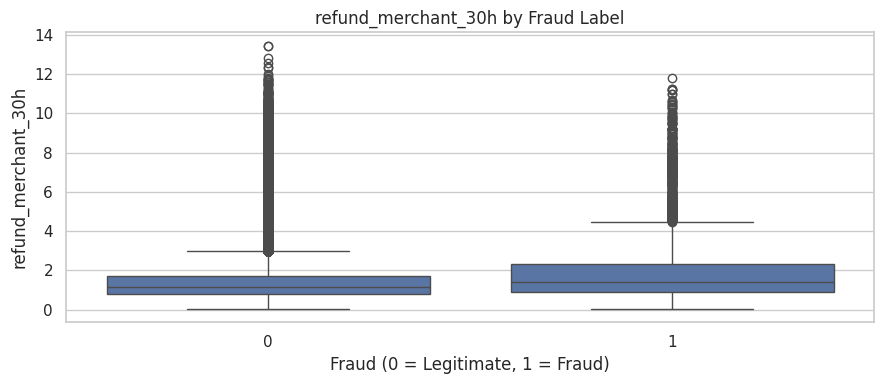

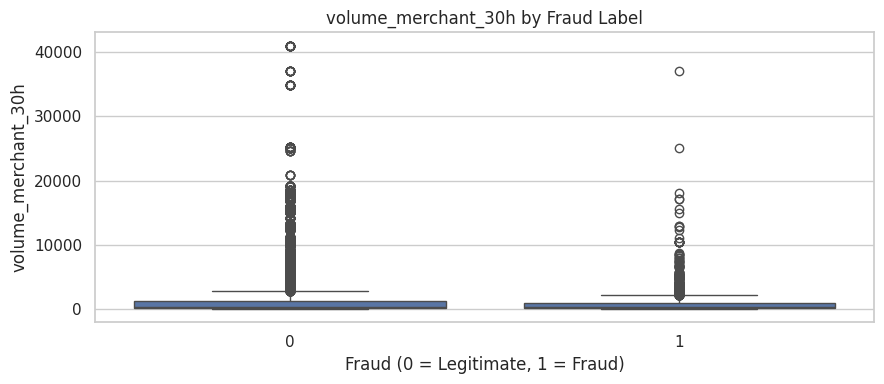

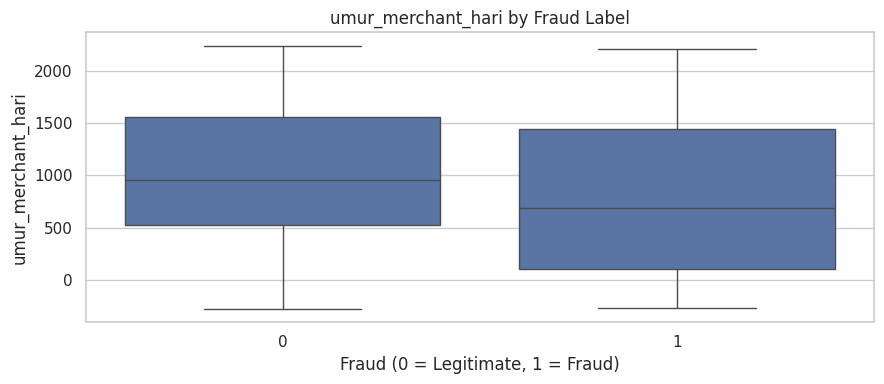


MERCHANT COVERAGE
Unique merchants: 7914
Median transactions per merchant: 17.0
Maximum transactions per merchant: 28085


In [54]:

# ==========================================
# TASK 2: MERCHANT FEATURE AUDIT
# ==========================================

merchant_features = [
    "refund_merchant_30h",
    "volume_merchant_30h",
    "umur_merchant_hari"
]

print("MERCHANT FEATURE SUMMARY")
display(
    cls_train.groupby("is_fraud")[merchant_features]
    .agg(["mean", "median", "std"])
)

print("\nMERCHANT FEATURE DISTRIBUTIONS")

for col in merchant_features:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=cls_train,
        x="is_fraud",
        y=col
    )

    plt.title(f"{col} by Fraud Label")
    plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
    plt.tight_layout()
    plt.show()

# Merchant-level transaction counts
merchant_counts = cls_train.groupby(
    "id_merchant"
).size()

print("\nMERCHANT COVERAGE")
print("Unique merchants:", cls_train["id_merchant"].nunique())
print("Median transactions per merchant:", merchant_counts.median())
print("Maximum transactions per merchant:", merchant_counts.max())


In [55]:
# Create chronological datasets
train_part = cls_train[cls_train["waktu"].dt.month <= 5].copy()
early_stop_part = cls_train[cls_train["waktu"].dt.month == 6].copy()
policy_part = cls_train[cls_train["waktu"].dt.month == 7].copy()
valid_part = cls_train[cls_train["waktu"].dt.month == 8].copy()

for name, df in [
    ("Training Jan-May", train_part),
    ("Early stopping June", early_stop_part),
    ("Policy selection July", policy_part),
    ("Final validation August", valid_part)
]:
    print(
        f"{name}: {len(df):,} rows | "
        f"{int(df['is_fraud'].sum()):,} fraud | "
        f"Fraud rate: {df['is_fraud'].mean():.4%}"
    )

Training Jan-May: 247,464 rows | 1,737 fraud | Fraud rate: 0.7019%
Early stopping June: 50,375 rows | 299 fraud | Fraud rate: 0.5935%
Policy selection July: 52,334 rows | 341 fraud | Fraud rate: 0.6516%
Final validation August: 52,904 rows | 245 fraud | Fraud rate: 0.4631%


In [56]:
!pip -q install catboost

In [57]:
from catboost import CatBoostClassifier
import catboost

print("CatBoost installed successfully.")
print("Version:", catboost.__version__)

CatBoost installed successfully.
Version: 1.2.10


In [58]:
# Check CatBoost availability
try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except ImportError:
    print("CatBoost is not installed.")

# Columns that must not be used as model features
excluded_cols = [
    "id_transaksi",       # identifier
    "waktu",              # used for chronological splitting
    "is_fraud",           # target
    "flag_review_manual"  # potential target leakage
]

# Candidate features
feature_cols = [
    col for col in cls_train.columns
    if col not in excluded_cols
]

# Detect categorical columns
cat_features = cls_train[feature_cols].select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Detect numerical columns
num_features = [
    col for col in feature_cols
    if col not in cat_features
]

print("Total candidate features:", len(feature_cols))
print("Categorical features:", len(cat_features))
print("Numerical features:", len(num_features))

print("\nCategorical columns:")
print(cat_features)

print("\nNumerical columns:")
print(num_features)

CatBoost version: 1.2.10
Total candidate features: 82
Categorical features: 6
Numerical features: 76

Categorical columns:
['id_pengguna', 'id_merchant', 'kategori_merchant', 'kanal', 'tipe_perangkat', 'email_domain']

Numerical columns:
['nominal', 'jam', 'hari_libur', 'umur_akun_hari', 'level_kyc', 'umur_pengguna_tahun', 'umur_perangkat_hari', 'perangkat_baru', 'jumlah_akun_per_perangkat', 'ganti_password_7h', 'gagal_login_24j', 'jarak_lokasi_km', 'negara_ip_beda', 'kartu_tidak_hadir', 'menit_sejak_trx_terakhir', 'trx_1j', 'trx_24j', 'trx_7h', 'nominal_24j', 'rasio_nominal_rata2', 'saldo_sebelum', 'persen_saldo', 'umur_merchant_hari', 'refund_merchant_30h', 'volume_merchant_30h', 'v01', 'v02', 'v03', 'v04', 'v05', 'v06', 'v07', 'v08', 'v09', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'v29', 'v30', 'v31', 'v32', 'v33', 'v34', 'v35', 'v36', 'v37', 'v38', 'v39', 'v40', 'v41', 'v42', 'v43', 'v44', '

In [59]:
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Prepare datasets
X_train = train_part[feature_cols].copy()
y_train = train_part["is_fraud"]

X_early = early_stop_part[feature_cols].copy()
y_early = early_stop_part["is_fraud"]

# Calculate class weights from training data
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
fraud_weight = neg_count / pos_count

print("Legitimate transactions:", neg_count)
print("Fraud transactions:", pos_count)
print("Fraud class weight:", round(fraud_weight, 2))

# Train baseline model
baseline_model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    cat_features=cat_features,
    random_seed=RANDOM_STATE,
    verbose=100,
    early_stopping_rounds=150,
    allow_writing_files=False
)

baseline_model.fit(
    X_train,
    y_train,
    eval_set=(X_early, y_early),
    use_best_model=True
)

# Evaluate on June early-stopping data
early_prob = baseline_model.predict_proba(X_early)[:, 1]

print("\nBest iteration:", baseline_model.best_iteration_)
print("June PR-AUC:", round(average_precision_score(y_early, early_prob), 5))
print("June ROC-AUC:", round(roc_auc_score(y_early, early_prob), 5))

Legitimate transactions: 245727
Fraud transactions: 1737
Fraud class weight: 141.47
0:	learn: 0.9400506	test: 0.9216703	best: 0.9216703 (0)	total: 1.93s	remaining: 48m 16s
100:	learn: 0.9953144	test: 0.9812598	best: 0.9812598 (100)	total: 1m 42s	remaining: 23m 43s
200:	learn: 0.9984418	test: 0.9821809	best: 0.9822320 (179)	total: 3m 3s	remaining: 19m 43s
300:	learn: 0.9995499	test: 0.9835736	best: 0.9835736 (300)	total: 4m 22s	remaining: 17m 25s
400:	learn: 0.9998902	test: 0.9834130	best: 0.9838091 (346)	total: 5m 48s	remaining: 15m 53s
500:	learn: 0.9999692	test: 0.9840333	best: 0.9840333 (500)	total: 7m 10s	remaining: 14m 19s
600:	learn: 0.9999882	test: 0.9843596	best: 0.9843909 (598)	total: 8m 35s	remaining: 12m 51s
700:	learn: 0.9999938	test: 0.9841026	best: 0.9844547 (605)	total: 9m 57s	remaining: 11m 21s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.9844546832
bestIteration = 605

Shrink model to first 606 iterations.

Best iteration: 605
June PR-AUC: 0.714

In [60]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Prepare July and August features
X_policy = policy_part[feature_cols].copy()
y_policy = policy_part["is_fraud"]

X_valid = valid_part[feature_cols].copy()
y_valid = valid_part["is_fraud"]

# Generate fraud probabilities
policy_prob = baseline_model.predict_proba(X_policy)[:, 1]
valid_prob = baseline_model.predict_proba(X_valid)[:, 1]

# Evaluate ranking performance
results = pd.DataFrame({
    "Period": ["June", "July", "August"],
    "PR-AUC": [
        average_precision_score(y_early, early_prob),
        average_precision_score(y_policy, policy_prob),
        average_precision_score(y_valid, valid_prob)
    ],
    "ROC-AUC": [
        roc_auc_score(y_early, early_prob),
        roc_auc_score(y_policy, policy_prob),
        roc_auc_score(y_valid, valid_prob)
    ],
    "Fraud cases": [
        int(y_early.sum()),
        int(y_policy.sum()),
        int(y_valid.sum())
    ]
})

display(results.round(5))

,Period,PR-AUC,ROC-AUC,Fraud cases
0,June,0.71420,0.98638,299
1,July,0.72229,0.98775,341
2,August,0.29620,0.95852,245


In [61]:
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

def evaluate_ranking(name, y, prob):
    y = np.asarray(y)
    prob = np.asarray(prob)

    print(f"\n{name}")
    print("-" * 40)
    print("Fraud rate:", round(y.mean(), 5))
    print("PR-AUC:", round(average_precision_score(y, prob), 5))
    print("Mean fraud score:", round(prob[y == 1].mean(), 5))
    print("Mean legitimate score:", round(prob[y == 0].mean(), 5))

    # Precision and recall among highest-scored transactions
    for pct in [0.1, 0.5, 1, 2]:
        n = max(1, int(len(y) * pct / 100))
        top_idx = np.argsort(prob)[-n:]
        precision = y[top_idx].mean()
        recall = y[top_idx].sum() / max(y.sum(), 1)

        print(
            f"Top {pct}%: "
            f"precision={precision:.4f}, "
            f"recall={recall:.4f}, "
            f"transactions={n}"
        )

evaluate_ranking("JULY", y_policy, policy_prob)
evaluate_ranking("AUGUST", y_valid, valid_prob)


JULY
----------------------------------------
Fraud rate: 0.00652
PR-AUC: 0.72229
Mean fraud score: 0.72841
Mean legitimate score: 0.01006
Top 0.1%: precision=0.8654, recall=0.1320, transactions=52
Top 0.5%: precision=0.8467, recall=0.6481, transactions=261
Top 1%: precision=0.5163, recall=0.7918, transactions=523
Top 2%: precision=0.2696, recall=0.8270, transactions=1046

AUGUST
----------------------------------------
Fraud rate: 0.00463
PR-AUC: 0.2962
Mean fraud score: 0.51959
Mean legitimate score: 0.01217
Top 0.1%: precision=0.4038, recall=0.0857, transactions=52
Top 0.5%: precision=0.4129, recall=0.4449, transactions=264
Top 1%: precision=0.2571, recall=0.5551, transactions=529
Top 2%: precision=0.1531, recall=0.6612, transactions=1058


In [62]:
importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": baseline_model.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance.head(20))

,feature,importance
2,kategori_merchant,11.600018
1,id_merchant,10.884992
5,nominal,7.251657
27,persen_saldo,7.117089
0,id_pengguna,5.324197
14,jumlah_akun_per_perangkat,5.245671
20,menit_sejak_trx_terakhir,2.813961
59,v29,2.740420
3,kanal,2.497722
12,umur_perangkat_hari,2.192995


In [63]:
# 1. Check unseen categorical values
categorical_drift = []

for col in cat_features:
    train_values = set(train_part[col].dropna().astype(str))

    for period_name, period_df in [
        ("July", policy_part),
        ("August", valid_part)
    ]:
        period_values = period_df[col].dropna().astype(str)
        unseen_rate = (~period_values.isin(train_values)).mean()

        categorical_drift.append({
            "feature": col,
            "period": period_name,
            "unseen_rate_pct": unseen_rate * 100,
            "unique_values": period_values.nunique()
        })

display(
    pd.DataFrame(categorical_drift)
    .round(2)
)

# 2. Compare numerical feature distributions
numeric_drift = []

for col in num_features:
    train_values = train_part[col].dropna()

    if train_values.nunique() < 2:
        continue

    # Use training quantiles as fixed comparison bins
    bins = np.unique(
        train_values.quantile(
            [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1]
        ).values
    )

    if len(bins) < 3:
        continue

    bins[0] = -np.inf
    bins[-1] = np.inf

    train_dist = pd.cut(
        train_part[col], bins=bins, include_lowest=True
    ).value_counts(normalize=True, sort=False)

    for period_name, period_df in [
        ("July", policy_part),
        ("August", valid_part)
    ]:
        period_dist = pd.cut(
            period_df[col], bins=bins, include_lowest=True
        ).value_counts(normalize=True, sort=False)

        # Small smoothing term avoids division by zero
        p = train_dist.values + 1e-6
        q = period_dist.values + 1e-6

        psi = np.sum((q - p) * np.log(q / p))

        numeric_drift.append({
            "feature": col,
            "period": period_name,
            "PSI": psi,
            "train_missing_pct": train_part[col].isna().mean() * 100,
            "period_missing_pct": period_df[col].isna().mean() * 100
        })

numeric_drift_df = pd.DataFrame(numeric_drift)

print("Largest numerical distribution changes:")
display(
    numeric_drift_df
    .sort_values(["period", "PSI"], ascending=[True, False])
    .groupby("period")
    .head(15)
    .round(3)
)

,feature,period,unseen_rate_pct,unique_values
0,id_pengguna,July,20.41,36011
1,id_pengguna,August,23.04,36554
2,id_merchant,July,1.58,6784
3,id_merchant,August,2.69,6945
4,kategori_merchant,July,0.00,24
5,kategori_merchant,August,0.00,24
6,kanal,July,0.00,5
7,kanal,August,0.00,5
8,tipe_perangkat,July,0.00,3
9,tipe_perangkat,August,0.00,3


Largest numerical distribution changes:


,feature,period,PSI,train_missing_pct,period_missing_pct
55,v15,August,1.937,0.000,0.000
17,menit_sejak_trx_terakhir,August,0.202,33.156,12.012
27,umur_merchant_hari,August,0.173,0.000,0.000
5,umur_akun_hari,August,0.072,0.000,0.000
11,umur_perangkat_hari,August,0.044,0.000,0.000
21,rasio_nominal_rata2,August,0.011,33.156,12.012
75,v26,August,0.004,0.000,0.000
97,v38,August,0.004,0.000,0.000
31,volume_merchant_30h,August,0.002,0.000,0.000
19,trx_7h,August,0.001,0.000,0.000


In [64]:
# Compare v15 distributions across time
periods = {
    "Train Jan-May": train_part,
    "June": early_stop_part,
    "July": policy_part,
    "August": valid_part
}

v15_summary = []

for name, df in periods.items():
    v = df["v15"]

    v15_summary.append({
        "period": name,
        "count": len(v),
        "mean": v.mean(),
        "std": v.std(),
        "min": v.min(),
        "p10": v.quantile(0.10),
        "median": v.median(),
        "p90": v.quantile(0.90),
        "max": v.max(),
        "fraud_rate": df["is_fraud"].mean()
    })

display(pd.DataFrame(v15_summary).round(4))

,period,count,mean,std,min,p10,median,p90,max,fraud_rate
0,Train Jan-May,247464,0.7494,1.0923,-3.832,-0.654,0.750,2.149,5.799,0.0070
1,June,50375,1.6503,0.9989,-2.285,0.376,1.654,2.934,6.017,0.0059
2,July,52334,1.9545,1.0027,-2.446,0.678,1.952,3.246,6.566,0.0065
3,August,52904,2.2660,1.0079,-1.975,0.980,2.265,3.557,6.991,0.0046


In [65]:
# Compare v15 values between legitimate and fraud transactions
v15_label_summary = []

for name, df in periods.items():
    for label in [0, 1]:
        subset = df.loc[df["is_fraud"] == label, "v15"]

        v15_label_summary.append({
            "period": name,
            "is_fraud": label,
            "count": len(subset),
            "mean": subset.mean(),
            "median": subset.median(),
            "std": subset.std()
        })

display(pd.DataFrame(v15_label_summary).round(4))

,period,is_fraud,count,mean,median,std
0,Train Jan-May,0,245727,0.7493,0.749,1.0924
1,Train Jan-May,1,1737,0.7740,0.827,1.0823
2,June,0,50076,1.6499,1.653,0.9988
3,June,1,299,1.7184,1.754,1.0093
4,July,0,51993,1.9542,1.952,1.0026
5,July,1,341,1.9958,1.998,1.0189
6,August,0,52659,2.2665,2.266,1.0080
7,August,1,245,2.1510,2.136,0.9846


In [66]:
# Create feature list without v15
feature_cols_no_v15 = [
    col for col in feature_cols if col != "v15"
]

# Train a comparison model
model_no_v15 = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    cat_features=cat_features,
    random_seed=RANDOM_STATE,
    verbose=100,
    early_stopping_rounds=150,
    allow_writing_files=False
)

model_no_v15.fit(
    train_part[feature_cols_no_v15],
    y_train,
    eval_set=(
        early_stop_part[feature_cols_no_v15],
        y_early
    ),
    use_best_model=True
)

# Evaluate July and August
prob_july_no_v15 = model_no_v15.predict_proba(
    policy_part[feature_cols_no_v15]
)[:, 1]

prob_aug_no_v15 = model_no_v15.predict_proba(
    valid_part[feature_cols_no_v15]
)[:, 1]

comparison = pd.DataFrame({
    "Period": ["June", "July", "August"],
    "Baseline PR-AUC": [
        average_precision_score(y_early, early_prob),
        average_precision_score(y_policy, policy_prob),
        average_precision_score(y_valid, valid_prob)
    ],
    "Without v15 PR-AUC": [
        average_precision_score(
            y_early,
            model_no_v15.predict_proba(
                early_stop_part[feature_cols_no_v15]
            )[:, 1]
        ),
        average_precision_score(y_policy, prob_july_no_v15),
        average_precision_score(y_valid, prob_aug_no_v15)
    ]
})

display(comparison.round(5))
print("Best iteration without v15:", model_no_v15.best_iteration_)

0:	learn: 0.9335333	test: 0.9094038	best: 0.9094038 (0)	total: 917ms	remaining: 22m 55s
100:	learn: 0.9955083	test: 0.9812224	best: 0.9813475 (87)	total: 1m 19s	remaining: 18m 18s
200:	learn: 0.9984439	test: 0.9826531	best: 0.9828054 (191)	total: 2m 38s	remaining: 17m 2s
300:	learn: 0.9995653	test: 0.9836963	best: 0.9837132 (298)	total: 4m	remaining: 15m 59s
400:	learn: 0.9998887	test: 0.9832889	best: 0.9839720 (318)	total: 5m 23s	remaining: 14m 47s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.9839719703
bestIteration = 318

Shrink model to first 319 iterations.


,Period,Baseline PR-AUC,Without v15 PR-AUC
0,June,0.71420,0.70629
1,July,0.72229,0.67916
2,August,0.29620,0.28999


Best iteration without v15: 318


In [67]:
# Remove customer and merchant IDs
identity_cols = ["id_pengguna", "id_merchant"]

feature_cols_no_identity = [
    col for col in feature_cols
    if col not in identity_cols
]

cat_features_no_identity = [
    col for col in cat_features
    if col not in identity_cols
]

model_no_identity = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    cat_features=cat_features_no_identity,
    random_seed=RANDOM_STATE,
    verbose=100,
    early_stopping_rounds=150,
    allow_writing_files=False
)

model_no_identity.fit(
    train_part[feature_cols_no_identity],
    y_train,
    eval_set=(
        early_stop_part[feature_cols_no_identity],
        y_early
    ),
    use_best_model=True
)

# Evaluate the three periods
prob_june_no_identity = model_no_identity.predict_proba(
    early_stop_part[feature_cols_no_identity]
)[:, 1]

prob_july_no_identity = model_no_identity.predict_proba(
    policy_part[feature_cols_no_identity]
)[:, 1]

prob_aug_no_identity = model_no_identity.predict_proba(
    valid_part[feature_cols_no_identity]
)[:, 1]

comparison_identity = pd.DataFrame({
    "Period": ["June", "July", "August"],
    "Baseline": [
        average_precision_score(y_early, early_prob),
        average_precision_score(y_policy, policy_prob),
        average_precision_score(y_valid, valid_prob)
    ],
    "Without v15": [
        average_precision_score(
            y_early,
            model_no_v15.predict_proba(
                early_stop_part[feature_cols_no_v15]
            )[:, 1]
        ),
        average_precision_score(y_policy, prob_july_no_v15),
        average_precision_score(y_valid, prob_aug_no_v15)
    ],
    "Without user/merchant IDs": [
        average_precision_score(y_early, prob_june_no_identity),
        average_precision_score(y_policy, prob_july_no_identity),
        average_precision_score(y_valid, prob_aug_no_identity)
    ]
})

display(comparison_identity.round(5))
print("Best iteration without IDs:", model_no_identity.best_iteration_)

0:	learn: 0.8919738	test: 0.8433543	best: 0.8433543 (0)	total: 1.37s	remaining: 34m 15s
100:	learn: 0.9910622	test: 0.9707529	best: 0.9707529 (100)	total: 1m 4s	remaining: 14m 58s
200:	learn: 0.9969922	test: 0.9705593	best: 0.9720486 (113)	total: 2m 3s	remaining: 13m 18s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.9720486226
bestIteration = 113

Shrink model to first 114 iterations.


,Period,Baseline,Without v15,Without user/merchant IDs
0,June,0.71420,0.70629,0.67833
1,July,0.72229,0.67916,0.70385
2,August,0.29620,0.28999,0.29982


Best iteration without IDs: 113


In [68]:
# Combine January-May and June
train_jan_jun = pd.concat(
    [train_part, early_stop_part],
    ignore_index=True
)

X_train_jan_jun = train_jan_jun[feature_cols]
y_train_jan_jun = train_jan_jun["is_fraud"]

# July becomes the early stopping set
X_july = policy_part[feature_cols]
y_july = policy_part["is_fraud"]

# Train using the same baseline configuration
model_recent = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    cat_features=cat_features,
    random_seed=RANDOM_STATE,
    verbose=100,
    early_stopping_rounds=150,
    allow_writing_files=False
)

model_recent.fit(
    X_train_jan_jun,
    y_train_jan_jun,
    eval_set=(X_july, y_july),
    use_best_model=True
)

# Evaluate on July and August
recent_july_prob = model_recent.predict_proba(X_july)[:, 1]
recent_aug_prob = model_recent.predict_proba(
    valid_part[feature_cols]
)[:, 1]

recent_comparison = pd.DataFrame({
    "Period": ["July", "August"],
    "Original baseline": [
        average_precision_score(y_policy, policy_prob),
        average_precision_score(y_valid, valid_prob)
    ],
    "Trained Jan-June": [
        average_precision_score(y_july, recent_july_prob),
        average_precision_score(y_valid, recent_aug_prob)
    ]
})

display(recent_comparison.round(5))
print("Best iteration:", model_recent.best_iteration_)

0:	learn: 0.9221567	test: 0.9250491	best: 0.9250491 (0)	total: 1.44s	remaining: 35m 59s
100:	learn: 0.9944541	test: 0.9877579	best: 0.9877579 (100)	total: 1m 36s	remaining: 22m 15s
200:	learn: 0.9977001	test: 0.9873605	best: 0.9879411 (110)	total: 3m 10s	remaining: 20m 29s
300:	learn: 0.9992895	test: 0.9883836	best: 0.9883836 (300)	total: 4m 48s	remaining: 19m 10s
400:	learn: 0.9997772	test: 0.9881090	best: 0.9884605 (312)	total: 6m 29s	remaining: 17m 46s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.9884605027
bestIteration = 312

Shrink model to first 313 iterations.


,Period,Original baseline,Trained Jan-June
0,July,0.72229,0.69810
1,August,0.29620,0.29158


Best iteration: 312


In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

# Use July predictions to learn a probability calibration mapping
# Platt scaling: logistic regression on the model's raw probability scores
calibrator = LogisticRegression()

calibrator.fit(
    policy_prob.reshape(-1, 1),
    y_policy
)

# Calibrate July and August probabilities
calibrated_july_prob = calibrator.predict_proba(
    policy_prob.reshape(-1, 1)
)[:, 1]

calibrated_aug_prob = calibrator.predict_proba(
    valid_prob.reshape(-1, 1)
)[:, 1]

# Compare calibration quality
calibration_results = pd.DataFrame({
    "Period": ["July", "August"],
    "Raw Brier score": [
        brier_score_loss(y_policy, policy_prob),
        brier_score_loss(y_valid, valid_prob)
    ],
    "Calibrated Brier score": [
        brier_score_loss(y_policy, calibrated_july_prob),
        brier_score_loss(y_valid, calibrated_aug_prob)
    ],
    "Actual fraud rate": [
        y_policy.mean(),
        y_valid.mean()
    ],
    "Mean calibrated probability": [
        calibrated_july_prob.mean(),
        calibrated_aug_prob.mean()
    ]
})

display(calibration_results.round(6))

,Period,Raw Brier score,Calibrated Brier score,Actual fraud rate,Mean calibrated probability
0,July,0.003839,0.002634,0.006516,0.006477
1,August,0.006128,0.004462,0.004631,0.005968


In [70]:
# Financial cost evaluation on August
REVIEW_COST = 25000

def calculate_financial_cost(y_true, nominal, prob, policy_name):
    y = np.asarray(y_true)
    amount = np.asarray(nominal, dtype=float)
    probability = np.asarray(prob, dtype=float)

    if policy_name == "No review":
        flagged = np.zeros(len(y), dtype=bool)
    elif policy_name == "Review everything":
        flagged = np.ones(len(y), dtype=bool)
    else:
        flagged = probability * amount > REVIEW_COST

    # Review cost applies to every flagged transaction
    review_cost = flagged.sum() * REVIEW_COST

    # Unflagged fraud causes transaction loss
    missed_fraud = (y == 1) & (~flagged)
    fraud_loss = amount[missed_fraud].sum()

    total_cost = review_cost + fraud_loss

    return {
        "Policy": policy_name,
        "Flagged transactions": int(flagged.sum()),
        "Flagged legitimate": int(((y == 0) & flagged).sum()),
        "Flagged fraud": int(((y == 1) & flagged).sum()),
        "Missed fraud": int(missed_fraud.sum()),
        "Review cost (Rp)": review_cost,
        "Fraud loss (Rp)": fraud_loss,
        "Total cost (Rp)": total_cost,
        "Cost per transaction (Rp)": total_cost / len(y)
    }


august_cost_results = pd.DataFrame([
    calculate_financial_cost(
        y_valid,
        valid_part["nominal"],
        calibrated_aug_prob,
        "No review"
    ),
    calculate_financial_cost(
        y_valid,
        valid_part["nominal"],
        calibrated_aug_prob,
        "Review everything"
    ),
    calculate_financial_cost(
        y_valid,
        valid_part["nominal"],
        calibrated_aug_prob,
        "Dynamic policy"
    )
])

display(august_cost_results.round(2))

,Policy,Flagged transactions,Flagged legitimate,Flagged fraud,Missed fraud,Review cost (Rp),Fraud loss (Rp),Total cost (Rp),Cost per transaction (Rp)
0,No review,0,0,0,245,0,250001200.0,2.500012e+08,4725.56
1,Review everything,52904,52659,245,0,1322600000,0.0,1.322600e+09,25000.00
2,Dynamic policy,396,274,122,123,9900000,109268200.0,1.191682e+08,2252.54


In [71]:
# Generate predictions for September-October test data
X_test = cls_test[feature_cols].copy()

# Raw fraud probabilities from baseline model
test_raw_prob = baseline_model.predict_proba(X_test)[:, 1]

# Apply the July-fitted probability calibrator
test_prob = calibrator.predict_proba(
    test_raw_prob.reshape(-1, 1)
)[:, 1]

# Apply the financial decision rule
test_flag = (
    test_prob * cls_test["nominal"].to_numpy(dtype=float)
    > 25000
).astype(int)

# Create submission file
submission_cls = pd.DataFrame({
    "id_transaksi": cls_test["id_transaksi"],
    "prob": test_prob,
    "tandai": test_flag
})

# Basic checks
print("Test rows:", len(submission_cls))
print("Missing values:", submission_cls.isna().sum().sum())
print("Duplicate transaction IDs:", submission_cls["id_transaksi"].duplicated().sum())
print("Flagged transactions:", submission_cls["tandai"].sum())
print("Flagging rate:", round(submission_cls["tandai"].mean() * 100, 3), "%")
print("Probability range:", submission_cls["prob"].min(), submission_cls["prob"].max())

# Save CSV
submission_cls.to_csv(
    "prediksi_klasifikasi.csv",
    index=False
)

print("\nSaved: prediksi_klasifikasi.csv")
display(submission_cls.head())

Test rows: 106674
Missing values: 0
Duplicate transaction IDs: 0
Flagged transactions: 865
Flagging rate: 0.811 %
Probability range: 0.00131609730673535 0.8964885199770339

Saved: prediksi_klasifikasi.csv


,id_transaksi,prob,tandai
0,T502861791,0.004705,0
1,T980390558,0.001326,0
2,T657838379,0.001318,0
3,T985886276,0.001318,0
4,T852019235,0.001402,0


In [72]:
from google.colab import files
files.download("prediksi_klasifikasi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>